## 4. Deploy the vector DB on your own, and implement the `vector cosine similarity` without using a high level library.


Deploy the Qdrant by running this Docker command:

docker run -p 6333:6333 qdrant/qdrant

In [15]:
from qdrant_client import QdrantClient

client = QdrantClient(url="http://localhost:6333")

# Retrieve points with vectors from the "midjourney" collection
points = client.retrieve(
    collection_name="midjourney",
    ids=[0],
    with_vectors=True,
)
vectors = {p.id: p.vector for p in points}
print(vectors)

{0: [0.056603346, -0.017431192, 0.022566801, -0.03675711, -5.0368373e-05, -0.028414536, 0.010363834, 0.001205015, -0.014284852, 0.031421855, 0.02215661, -0.013723722, 0.034976754, 0.0029026119, 0.015109472, 0.015157796, -0.01787591, 0.028847031, -0.0031357834, -0.003914772, -0.049326833, -0.0033250465, 0.0340123, 0.002838062, 0.03117119, 0.03854251, 0.025851095, 0.0071173958, -0.0052507613, 0.03431978, 0.00945399, -0.003432748, 0.015274429, -0.001151669, -0.00916981, 0.0009046381, 0.00993646, -0.022976415, -0.028335258, 0.12201825, -0.018433489, 0.01729716, 0.0011538727, -0.00453327, -0.012006804, -0.00695464, -0.0009389036, -0.017737864, 0.028426848, 0.008044113, -0.0066634873, -0.018861907, -0.015471467, 0.004663111, -0.031021079, -0.0045815636, 0.019427326, -0.009931858, -0.0031636418, -0.0068293093, -0.058928736, -0.036148265, 0.0028075206, 1.980497e-06, -0.0630603, 0.020620698, -0.039764915, -0.00448787, -0.04331754, -0.015278464, -0.025409061, 0.007911117, 0.035908535, -0.0015704

Official Qdrant way to do Cosine Sim

In [16]:
results = client.query_points(
    collection_name="midjourney",
    query=vectors[0],
    limit=5,
).points

for r in results:
    print(r.id, r.payload["name"], round(r.score, 4))

0 Chris Dyer 1.0
3971 Guy Aitchison 0.9223
1224 Huichol art 0.9163
2891 Psychedelic art 0.8898
1932 Tracy Scott 0.8882


Manual implementation

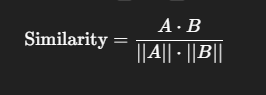 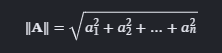

In [ ]:
import math

def cosine_similarity(vec_a, vec_b):
    dot = 0.0
    len_a = 0.0
    len_b = 0.0
    for a, b in zip(vec_a, vec_b):
        dot += a * b        # A · B (Numerator)
        len_a += a * a      # running sum of A[i] squared
        len_b += b * b      # running sum of B[i] squared
    denominator = math.sqrt(len_a) * math.sqrt(len_b)  # ||A|| * ||B||
    cosine = dot / denominator
    return cosine

Loop through the Qdrant "midjourney" collection 

In [20]:
scores = [] # to keep track of the cosine similarity scores for each point

offset = None
while True:
    batch, offset = client.scroll(
        collection_name="midjourney",
        limit=100,            # points per page
        offset=offset,        # where to continue from (None = start)
        with_vectors=True,
        with_payload=True,
    )
    
    for point in batch:
        scores.append((point.id, cosine_similarity(vectors[0], point.vector)))
        
    if offset is None:
        break  # no more points to retrieve
    
# Sort the scores in descending order and get the top 5
top_5 = sorted(scores, key=lambda x: x[1], reverse=True)[:5]
print(top_5)

[(0, 0.9999999999999999), (3971, 0.9223467034803691), (1224, 0.9163347112597761), (2891, 0.8898214223962881), (1932, 0.8881910504912738)]


As we can see the top 5 output of the built-in method and the manually written vector cosine similarity is the same.

The only difference is my manual version does the search manually by looping through the whole collection, get their score and sort them. This can get slower as data grows, which is not scalable. Meanwhile, Qdrant uses HNSW index to find near neighbors without checking everything.